<a href="https://colab.research.google.com/github/nuralamsm2-ops/SM/blob/main/ML5sem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

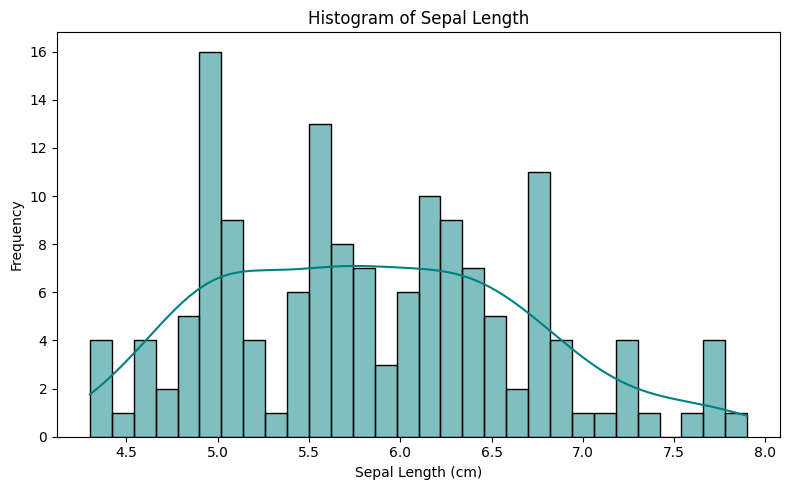

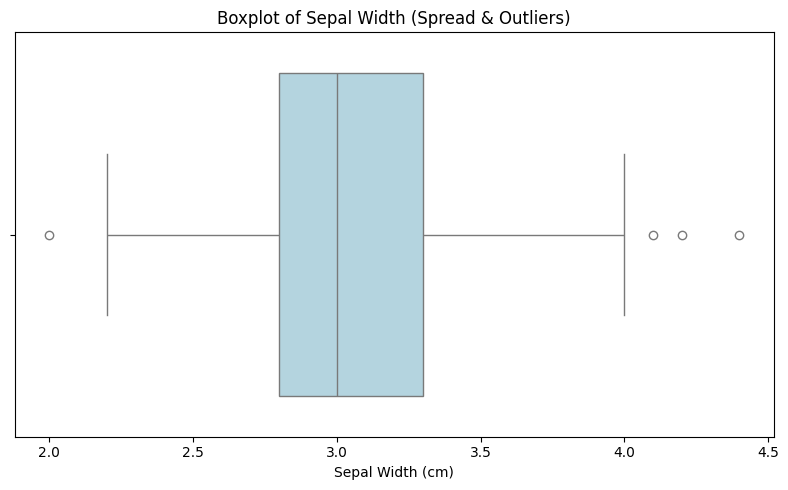

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = sns.load_dataset("iris")

# Histogram
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="sepal_length", bins=30, kde=True, color="teal")
plt.title("Histogram of Sepal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("histogram_SLength.png", dpi=300)
plt.show()

# Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="sepal_width", color="lightblue")
plt.title("Boxplot of Sepal Width (Spread & Outliers)")
plt.xlabel("Sepal Width (cm)")
plt.tight_layout()
plt.savefig("boxplot_sepal_width.png", dpi=300)
plt.show()

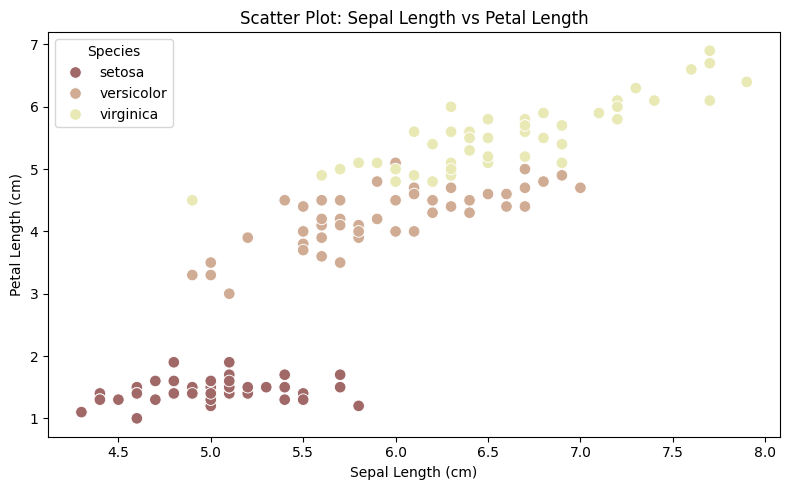

/tmp/ipykernel_708/486691637.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='species', y='petal_length', data=df,


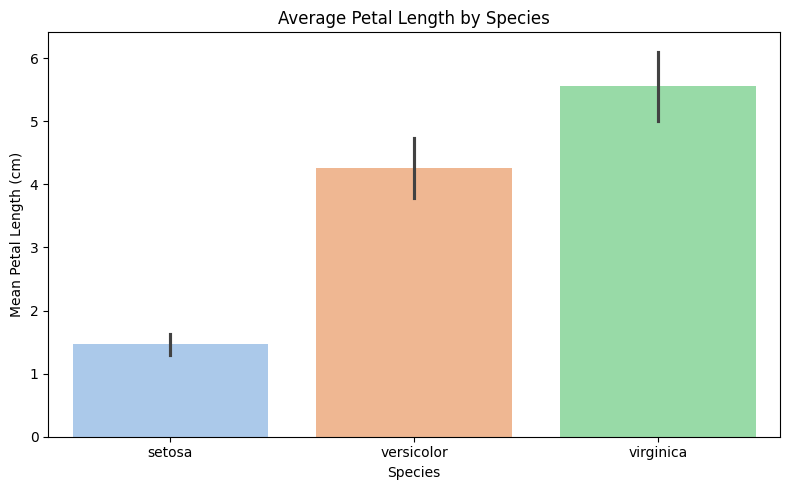

In [ ]:
# ---------- Scatter Plot ----------
plt.figure(figsize=(8, 5))
sns.scatterplot(x='sepal_length', y='petal_length', hue='species',
                 palette='pink', s=70, data=df)
plt.title('Scatter Plot: Sepal Length vs Petal Length')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Length (cm)')
plt.legend(title='Species')
plt.tight_layout()
plt.savefig('scatter_sepal_petal.png')
plt.show()

# ---------- Bar Chart (categorical vs numeric aggregate) ----------
plt.figure(figsize=(8, 5))
sns.barplot(x='species', y='petal_length', data=df,
            estimator='mean', errorbar='sd', palette='pastel')
plt.title('Average Petal Length by Species')
plt.xlabel('Species')
plt.ylabel('Mean Petal Length (cm)')
plt.tight_layout()
plt.savefig('barplot_species_petal.png')
plt.show()

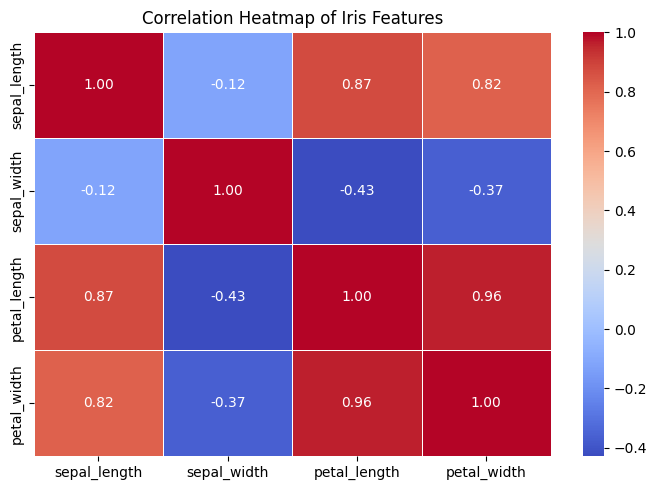

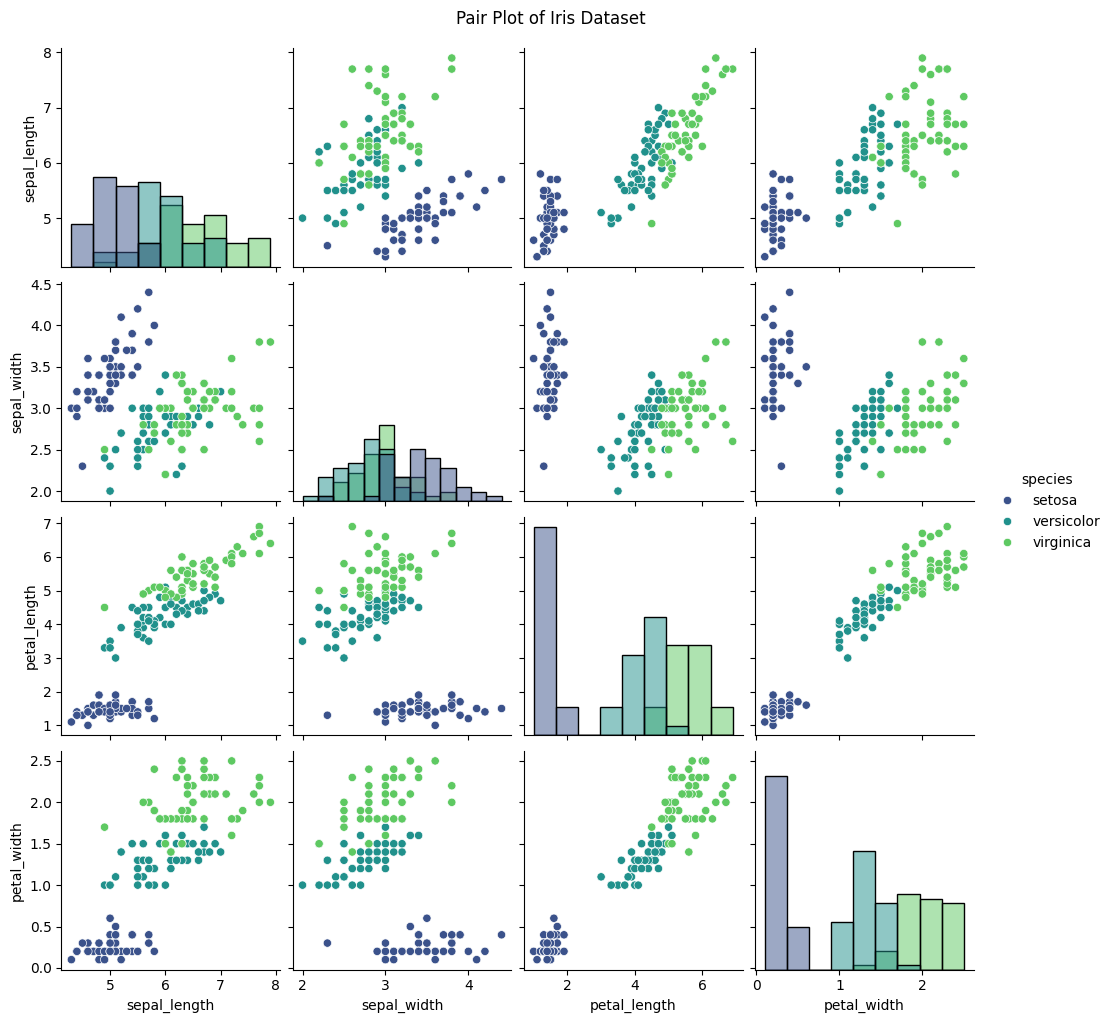

In [ ]:
# ---------- Correlation Heatmap ----------
plt.figure(figsize=(7, 5))
# select only numeric columns before computing correlation
numeric_df = df.drop(columns='species')
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Iris Features')
plt.tight_layout()
plt.savefig('heatmap_iris.png')
plt.show()

# ---------- Pair Plot ----------
sns.pairplot(df, hue='species', palette='viridis', diag_kind='hist')
plt.suptitle('Pair Plot of Iris Dataset', y=1.02)
plt.savefig('pairplot_iris.png')
plt.show()

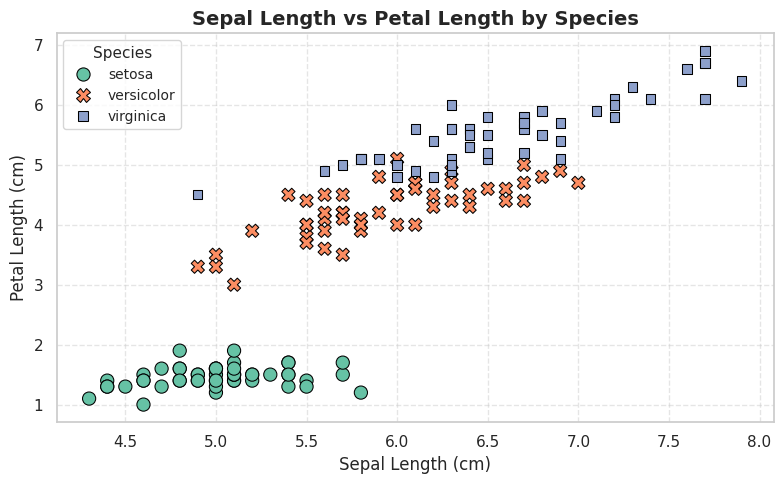

/tmp/ipykernel_708/1985591357.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='species', y='sepal_width', data=df, palette='coolwarm', estimator='mean')


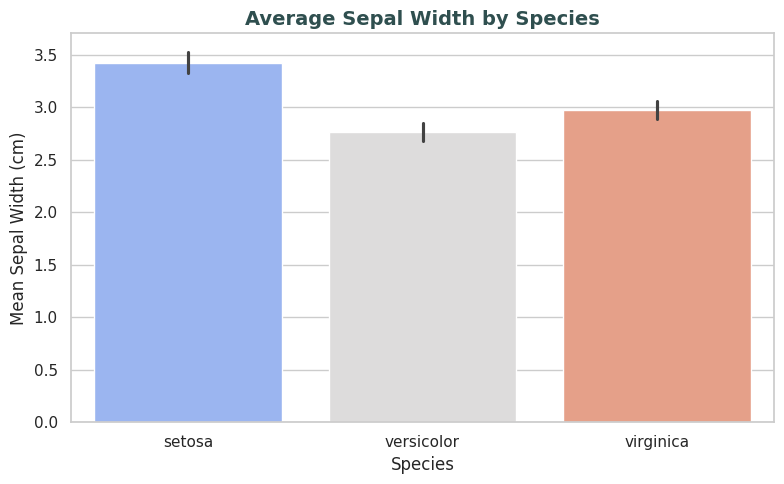

In [ ]:
# ---------- Set a theme/style globally ----------
sns.set_theme(style='whitegrid', palette='deep')  # try 'darkgrid', 'ticks', 'muted', 'pastel' too

# ---------- Customized Scatter Plot ----------
plt.figure(figsize=(8, 5))
scatter = sns.scatterplot(
    x='sepal_length', y='petal_length',
    hue='species', style='species',
    palette='Set2', s=90, edgecolor='black', data=df
)

plt.title('Sepal Length vs Petal Length by Species', fontsize=14, fontweight='bold')
plt.xlabel('Sepal Length (cm)', fontsize=12)
plt.ylabel('Petal Length (cm)', fontsize=12)
plt.legend(title='Species', title_fontsize=11, fontsize=10, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save in high resolution
plt.savefig('customized_scatter_iris.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------- Customized Bar Plot with a different palette ----------
plt.figure(figsize=(8, 5))
sns.barplot(x='species', y='sepal_width', data=df, palette='coolwarm', estimator='mean')

plt.title('Average Sepal Width by Species', fontsize=14, fontweight='bold', color='darkslategray')
plt.xlabel('Species', fontsize=12)
plt.ylabel('Mean Sepal Width (cm)', fontsize=12)
plt.tight_layout()

plt.savefig('customized_barplot_iris.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Let's use sepal_length, sepal_width, and petal_width to predict petal_length
X = df[['sepal_length', 'sepal_width', 'petal_width']]
y = df['petal_length']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

# Predict
y_pred_lr = linear_model.predict(X_test_scaled)

# Display predictions
print("First 10 predictions:", y_pred_lr[:10])

First 10 predictions: [4.12771597 1.882002   7.02565911 4.43211007 4.92719101 2.06623661
 3.84947941 6.12949916 5.02174454 3.97445323]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae_lr = mean_absolute_error(
    y_test,
    y_pred_lr
)

mse_lr = mean_squared_error(
    y_test,
    y_pred_lr
)

rmse_lr = np.sqrt(mse_lr)

r2_lr = r2_score(
    y_test,
    y_pred_lr
)
# Print:
print("Linear Regression")
print("-------------------------")
print("MAE :", mae_lr)
print("MSE :", mse_lr)
print("RMSE:", rmse_lr)
print("R²  :", r2_lr)

Linear Regression
-------------------------
MAE : 0.26051798462523845
MSE : 0.13001626031382657
RMSE: 0.3605776758395153
R²  : 0.9603293155857665


In [ ]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)
y_pred_dt = dt_model.predict(
    X_test
)

In [ ]:
mae_dt = mean_absolute_error(
    y_test,
    y_pred_dt
)

mse_dt = mean_squared_error(
    y_test,
    y_pred_dt
)

rmse_dt = np.sqrt(mse_dt)

r2_dt = r2_score(
    y_test,
    y_pred_dt
)

print("Decision Tree")
print("-------------------------")
print("MAE :", mae_dt)
print("MSE :", mse_dt)
print("RMSE:", rmse_dt)
print("R²  :", r2_dt)

Decision Tree
-------------------------
MAE : 0.33833333333333326
MSE : 0.15508333333333335
RMSE: 0.3938062129186554
R²  : 0.9526808265387419


In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)
y_pred_rf = rf_model.predict(
    X_test
)

In [ ]:

mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

mse_rf = mean_squared_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

print("Random Forest")
print("-------------------------")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest
-------------------------
MAE : 0.26999365079365056
MSE : 0.10166896100982559
RMSE: 0.3188557056253276
R²  : 0.9689786703816239


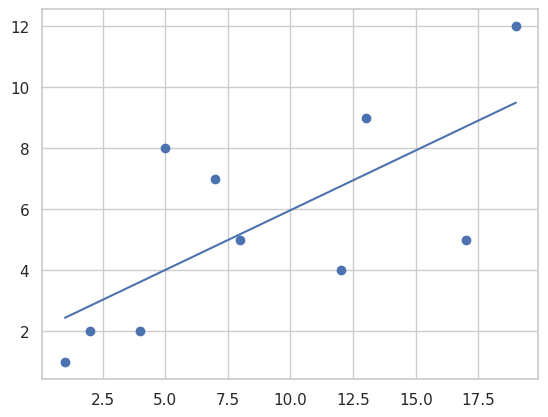

In [ ]:
import matplotlib.pyplot as plt
from scipy import stats
x=[1,2,4,5,7,8,12,13,17,19]
y=[1,2,2,8,7,5,4,9,5,12]
slope,intercept,r,p,std_err=stats.linregress(x,y)
def myfunc(x):
  return slope*x+intercept
mymodel=list(map(myfunc,x))
plt.scatter(x,y)
plt.plot(x,mymodel)
plt.show()

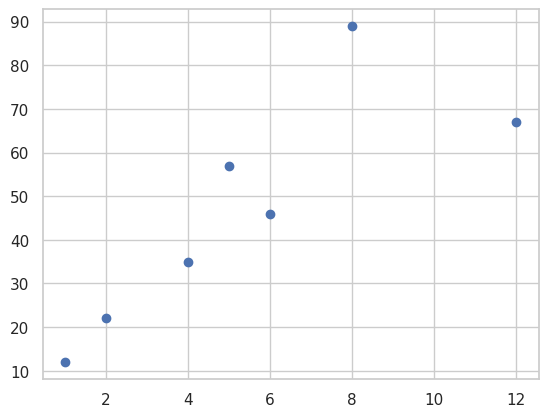

In [ ]:
import matplotlib.pyplot as plt
x=[1,2,4,6,5,8,12]
y=[12,22,35,46,57,89,67]
plt.scatter(x,y)
plt.show()

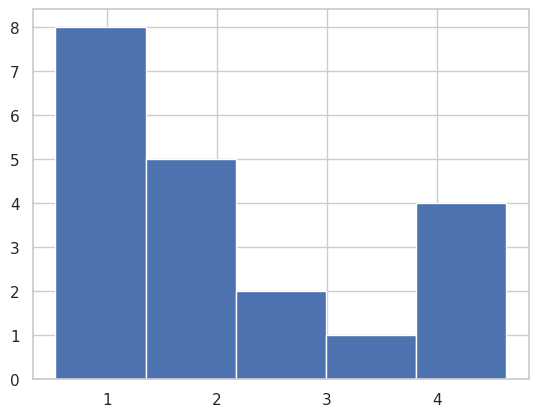

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
x=np.random.uniform(0.5,5.0,20)
plt.hist(x,5)
plt.show()

In [ ]:
import numpy as np
x=np.random.uniform(0.5,5.0,20)
print(x)

[3.10848881 1.78321305 4.48882897 1.48037941 3.43826073 2.3531495
 2.03090437 1.07785999 4.52889012 1.77617292 4.72400993 0.72376112
 1.63776689 0.87766684 4.10712915 4.15071499 2.67761982 4.7082867
 4.20943437 4.58910133]


In [ ]:
import statistics as st
x=[20,40,54,34,12,46,79]
y=st.mode (x)
print(y)

20


In [ ]:
import numpy as np
x=[20,40,54,34,12,46,79]
y=np.median(x)
print(y)

40.0


In [ ]:
import numpy as np
x=[87,54,34,20,46,282,34]
y=np.mean(x)
print (y)

79.57142857142857


In [ ]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

try:
    df = pd.read_csv('/content/KT_GameBox_1 (3).csv')
    print("Successfully loaded KT_GameBox_1 (3).csv")
except FileNotFoundError:
    print("CSV file not found. Falling back to the 'penguins' dataset.")
    df = sns.load_dataset('penguins')

CSV file not found. Falling back to the 'penguins' dataset.


In [ ]:
df = sns.load_dataset('penguins')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [ ]:
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Drop rows with any missing values, as Logistic Regression doesn't handle NaNs by default.
df_cleaned = df.dropna().copy()

# Define features (X) and target (y)
X = df_cleaned.drop('species', axis=1)
y = df_cleaned['species']

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

# Create preprocessing pipelines for numerical and categorical features
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Create a column transformer to apply different transformations to different columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Apply preprocessing to training and testing data
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Data preprocessing complete. X_train_scaled, X_test_scaled, y_train, y_test are defined.")

Data preprocessing complete. X_train_scaled, X_test_scaled, y_train, y_test are defined.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(X_test_scaled)

accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print("Logistic Regression Accuracy:",
      accuracy_lr)
print(
    "Accuracy:",
    accuracy_lr * 100,
    "%"
)

Logistic Regression Accuracy: 0.99
Accuracy: 99.0 %


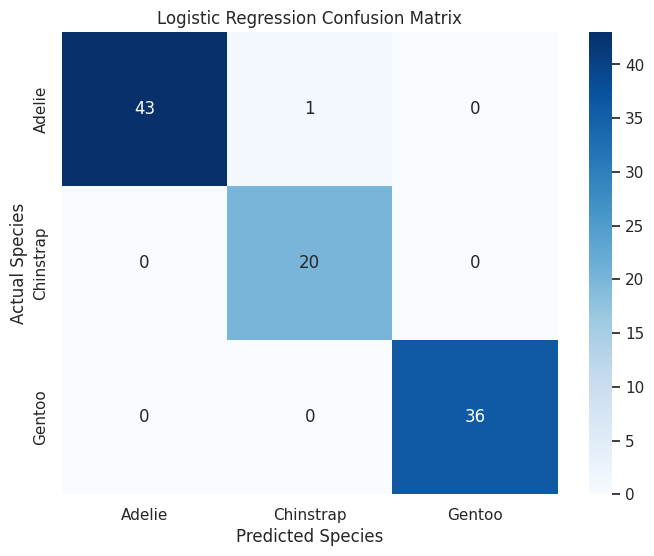

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Initialize and train the model to guarantee it is defined
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lr = logistic_model.predict(X_test_scaled)

# Get the sorted unique class labels from the test set
class_labels = np.unique(y_test)

cm = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=class_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test_scaled
)

accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print(
    "KNN Accuracy:",
    accuracy_knn * 100,
    "%"
)

KNN Accuracy: 100.0 %


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(
    X_train_scaled,
    y_train
)

y_pred_dt = dt_model.predict(X_test_scaled)

accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print(
    "Decision Tree Accuracy:",
    accuracy_dt * 100,
    "%"
)

Decision Tree Accuracy: 95.0 %


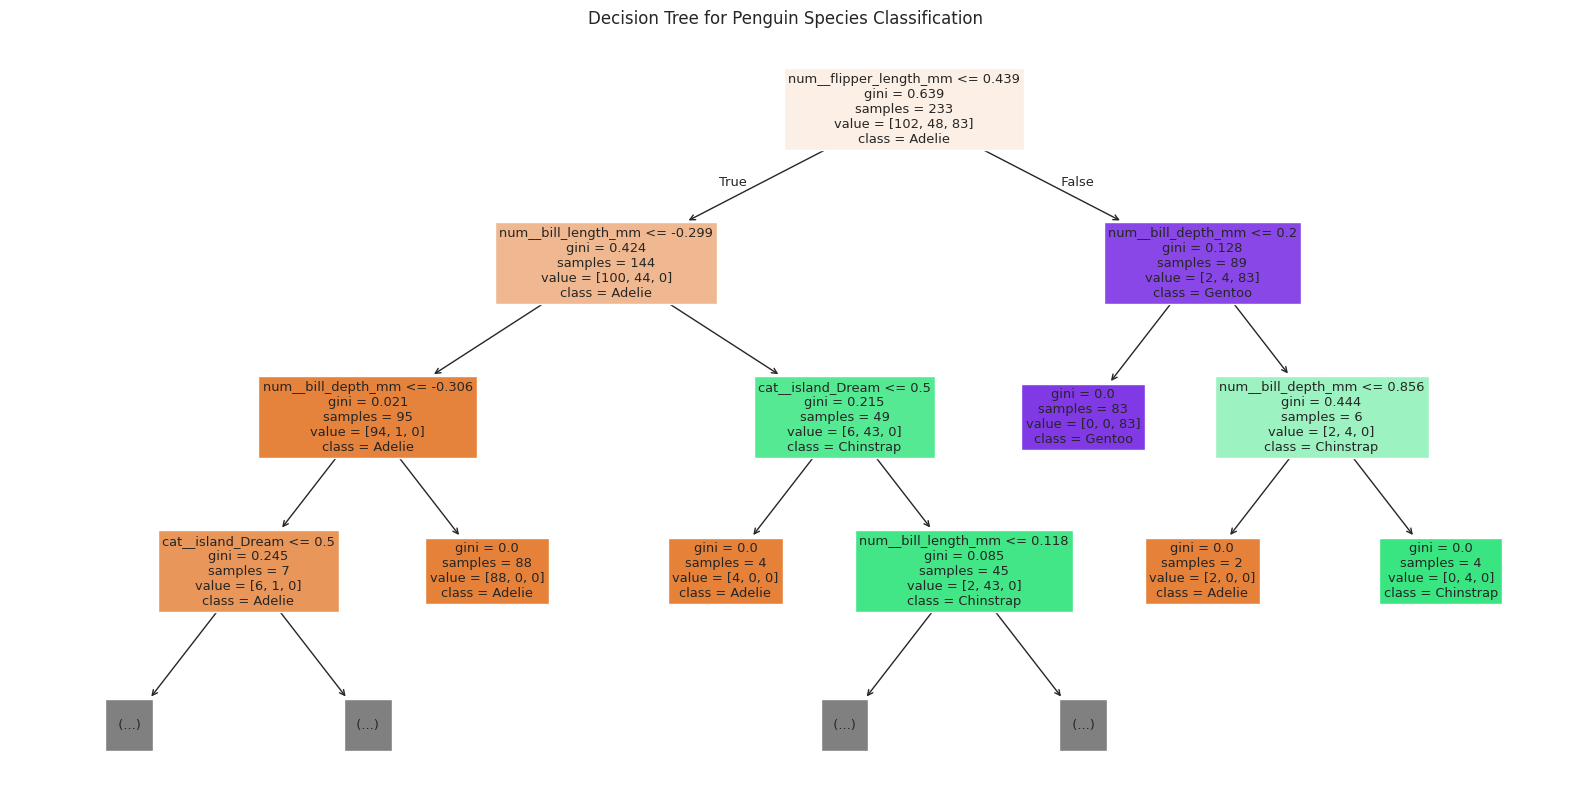

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
import numpy as np

# Get correct feature names from the preprocessor pipeline
feature_names = preprocessor.get_feature_names_out()

# Extract unique classes from your target data
class_names = np.unique(y_train)

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    max_depth=3
)

plt.title("Decision Tree for Penguin Species Classification")

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_scaled,
    y_train
)

y_pred_rf = rf_model.predict(X_test_scaled)

accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    accuracy_rf * 100,
    "%"
)

Random Forest Accuracy: 100.0 %


In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

# Note: LinearRegression may raise a ValueError since y_train contains string categories ('species')
try:
    linear_model.fit(
        X_train_scaled,
        y_train
    )
except ValueError as e:
    print(f"Expected Training Error: {e}")

# Predict:
try:
    y_pred_lr = linear_model.predict(
        X_test_scaled
    )
    # Display:
    print(y_pred_lr[:10])
except Exception as e:
    print(f"Prediction could not be completed: {e}")

Expected Training Error: could not convert string to float: 'Gentoo'
Prediction could not be completed: This LinearRegression instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
